# $(\mu_K, \mu_B)$ plane

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, _find_muB_muK_star

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

def PNM_n(nB, Temp, param=para.paraQMCRMF3):
    pre = RMFpressurePNM(
        input_num = nB,
        input_type = "nB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

n0 = 0.16 * const.MeV_fm**3

ImportError: cannot import name 'vNtoQ_Pc' from 'RMFsolver.phase_velocity' (/Users/janshao/NSM_related/RMFsolver/phase_velocity.py)

In [ ]:
T = 15
n_crit = 2.5 * n0
Deln = 0.05 * n_crit
m_s = 0
param = para.paraQMCRMF3
NM_type = "PNM"
aQmax = True

# solve for bag constant
P_crit = PNM_n(n_crit, T)
P_diff = lambda x: PNM(x, T) - P_crit
muB_crit = fsolve(P_diff, 1050)[0]
PQM_solve_for_B = lambda x: PQM(muB_crit, 0, x, T, m_s) - P_crit
B_SQM = fsolve(PQM_solve_for_B, 180)[0]

# solve for points Q and N at beta eq.
DelP = PNM_n(n_crit + Deln, T) - P_crit
PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
muB_N = fsolve(PNM_minus_PShift, 1050)[0]

PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]

# calculating aQstar
if aQmax:
    epsilon = np.sqrt(np.finfo(float).eps)
    muB_star, muK_star = _find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
    PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
    grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
    nB_Qstar = grad_Qstar[0]
    nK_Qstar = grad_Qstar[1]
    grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
    nB_Q = grad_Q[0]
    nK_Q = grad_Q[1]
    aQstar = (nK_Qstar - nK_Q)/nB_Q  

else:
    PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
    PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
    ddPQM_ddmuK = Derivative(PQM_muK, n=2)
    dPQM_dmuK = Derivative(PQM_muK, n=1)
    dPQM_dmuB = Derivative(PQM_muB, n=1)
    chiK_Q = ddPQM_ddmuK(0)
    nB_Q = dPQM_dmuB(muB_Q)
    nK_Q = dPQM_dmuK(0)
    aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
    muK_star = np.sqrt(2 * nB_Q * (muB_N - muB_Q) / chiK_Q)
    PQM_solve_for_muBstar = lambda x: PQM(x, muK_star, B_SQM, T, m_s) - P_crit
    muB_star = fsolve(PQM_solve_for_muBstar, muB_Q)[0]

# calculating aN
PNM_wrap = lambda x: PNM(x, T)
dPNM_dmuB = Derivative(PNM_wrap, n=1)
nB_N = dPNM_dmuB(muB_N)
aN = (nB_N - nK_Q) / nB_Q   

muQ = muB_star/3

alpha_s = 0.3
g_s = np.sqrt(4 * np.pi * alpha_s)

# Compute intermediate quantities
etaQ = (9 * np.pi**2 * T**2) / muQ**2
tauQ = 1.98e12 * ((300 / muQ)**5)
qD = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
h = 1.81317

part1 = h*T**(5/3)/qD**(2/3)
part2 = np.pi**3 * T**2 / (12*qD)

DQ = 1/( 24*alpha_s**2/np.pi * ( part1 + part2 ) )
# DQ = (np.pi / (24 * (0.3)**2 * 1.81 * T**(5/3))) * ((6 * 0.3 / np.pi * muQ**2)**(1/3))

# Compute v_N->Q
vNQ = np.sqrt((DQ / tauQ) * ((aQstar**4 + 2 * etaQ * aQstar**2) / (2 * aN * (aN - aQstar)))) * 3e8

print(" muQ       =", muQ, ';\n', "aQstar    =", aQstar, ';\n', "aN        =", aN, ';\n', "vNQ       =", vNQ, "/(3*^8);")

 muQ       = 372.07147392414066 ;
 aQstar    = 0.2408819152932963 ;
 aN        = 0.5966564566604293 ;
 vNQ       = 39.427802491078864 /(3*^8);


In [ ]:
from RMFsolver.phase_velocity import PQM, extract_contour_coords_num, extract_contour_coords_ana
import numpy as np
import matplotlib.pyplot as plt

muK_lim= 90

muK_list = np.linspace(-muK_lim, muK_lim, 100)
muB_coords, muK_coords = extract_contour_coords_ana(lambda x, y:PQM(x, y, B_SQM, 15, 0), (1050, 1150), muK_list, level=P_crit+DelP, )

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

factor = 1.2

plt.figure(figsize=[7, 5.5])
plt.rcParams["figure.dpi"] = 150
mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern for math only
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
})

plt.plot(muB_coords, muK_coords, 'r')
plt.plot(np.linspace(1095, 1145, 100), np.zeros(100), 'k')
plt.xlim(1100, 1145)
plt.ylim(-muK_lim, muK_lim)

#plt.title(r"Isobar for $T=15$ MeV, $n_{crit} = 2.5 n_0$, $\Delta n = n_0/8$", fontsize=14)
plt.xlabel(r"$\mu_B$ (MeV)", fontsize=16)
plt.ylabel(r"$\mu_K$ (MeV)", fontsize=16)

plt.scatter(muB_Q, 0, s=50, c='r')
plt.text(muB_Q+0.5, -14, r"$\mathbf{\bar Q}$", c='r', fontsize=18)

plt.scatter(muB_N, 0, s=50, c='b')
plt.text(muB_N+0.5, -14, r"$\mathbf{\bar N}$", c='b', fontsize=18)

plt.scatter(muB_star, muK_star, s=100, c='r', marker='*')
plt.text(muB_star, muK_star+5, r"$\mathbf{Q^*}$", c='r', fontsize=18)

#plt.plot(muB_Q*np.ones(25), np.linspace(-100, 0, 25), ".", markersize=1, color='k')
#plt.text(muB_Q-2.0, -82, rf"$\mu_B^{{\bar Q}} = {muB_Q:.1f}$", rotation=90, fontsize=13)

#plt.plot(muB_N*np.ones(25), np.linspace(-100, 0, 25), ".", markersize=1, color='k')
#plt.text(muB_N-2.0, -82, rf"$\mu_B^{{\bar N}} = {muB_N:.1f}$", rotation=90, fontsize=13)

#plt.plot(muB_star*np.ones(20), np.linspace(0, muK_star, 20), ".", markersize=1, color='k')
#plt.text(muB_star-2.0, 14, rf"$\mu_B^{{Q^*}} = {muB_star:.1f}$", rotation=90, fontsize=13)

#plt.plot(np.linspace(1090, muB_star, 25), muK_star*np.ones(25), ".", markersize=1, color='k')
#plt.text(1103, muK_star+4, rf"$\mu_K^{{Q^*}} = {muK_star:.1f}$", fontsize=13)

plt.text(1107, -79, rf"Quark matter isobar", rotation=42, c='r', fontsize=16)

# arrows from Q to
plt.text(1108, 5, rf"$x<0$", c='b', fontsize=16)
x1 = np.linspace(muB_Q, 1140, 10)
y1 = np.full_like(x1, -2)         # vertical offset only
u1 = np.full_like(x1, 1.0)          # horizontal length in data units
v1 = np.zeros_like(x1)              # no vertical component
plt.quiver(
    x1, y1, u1, v1,
    angles='xy', scale_units='xy', scale=1,
    color='r',
    width=0.002 * factor,       # shaft thicker
    headwidth=4 * factor,       # head wider
    headlength=5 * factor,      # head longer
    headaxislength=4 * factor,  # axis length
    linewidths=0.6 * factor     # outline thicker
)

# from  to N
plt.text(1138, -9, rf"$x\to\infty$", c='r', fontsize=16)
x2 = np.linspace(1110, muB_N-1, 10)
y2 = np.full_like(x1, 2)         # vertical offset only
u2 = np.full_like(x1, 1.0)          # horizontal length in data units
v2 = np.zeros_like(x1)              # no vertical component
plt.quiver(
    x2, y2, u2, v2,
    angles='xy', scale_units='xy', scale=1,
    color='b',
    width=0.002 * factor,       # shaft thicker
    headwidth=4 * factor,       # head wider
    headlength=5 * factor,      # head longer
    headaxislength=4 * factor,  # axis length
    linewidths=0.6 * factor     # outline thicker
)

# --- arrows along the red isobar FROM Q* -> Q (bigger + offset) ---
# indices closest to Q* and Q on the curve
i_star = np.argmin(np.abs(muK_coords - muK_star))
i_Q    = np.argmin(np.abs(muK_coords - 0.0))   # Q is at mu_K = 0

# always march from Q* to Q
sign = 1 if i_Q > i_star else -1
seg_len = abs(i_Q - i_star)
step = max(1, seg_len // 8)                     # ~8 arrows; smaller -> denser
idx = np.arange(i_star, i_Q, sign * step)
idx_next = idx + sign                           # forward neighbor

# tangent (Q* -> Q)
dX = muB_coords[idx_next] - muB_coords[idx]
dY = muK_coords[idx_next] - muK_coords[idx]

# unit tangent
L = np.hypot(dX, dY)
tx = np.zeros_like(dX); ty = np.zeros_like(dY)
m = L > 0
tx[m] = dX[m] / L[m]
ty[m] = dY[m] / L[m]

# pick a fixed length in data units
arrow_len = 4.0
U = arrow_len * tx
V = arrow_len * ty

# offset arrows off the curve along the normal
nx = np.zeros_like(tx); ny = np.zeros_like(ty)
nx[m] = -ty[m]            # normal = (-ty, tx)
ny[m] =  tx[m]

offset = 1.0              # <-- move arrows away from line; flip sign if needed
X = muB_coords[idx] + offset * nx
Y = muK_coords[idx] + offset * ny

plt.quiver(
    X, Y, U, V,
    angles='xy', scale_units='xy', scale=1,
    color='r',
    width=0.002 * factor,       # shaft thicker
    headwidth=4 * factor,       # head wider
    headlength=5 * factor,      # head longer
    headaxislength=4 * factor,  # axis length
    linewidths=0.6 * factor     # outline thicker
)


from matplotlib.patches import FancyArrowPatch
ax = plt.gca()

plt.text(1122, 10, rf"Crossing phase boundary", c='g', fontsize=13, rotation=130+180)
arc = FancyArrowPatch(
    (muB_N, 0), (muB_star, muK_star),
    connectionstyle="arc3,rad=0.45",   # ↑ bigger → more “up”; flip sign if wrong way
    arrowstyle="-|>", mutation_scale=16,
    linestyle=(0,(6,4)), lw=2, color="seagreen", zorder=3
)
ax.add_patch(arc)

plt.tick_params(which='both', direction='in', top=True, right=True)
plt.xticks([1100, 1110, 1120, 1130, 1140])
plt.yticks([-60, -30, 0, 30, 60, 90])

plt.savefig("muB_muK_Plane.pdf", bbox_inches="tight")

NameError: name 'muB_coords' is not defined

<Figure size 700x550 with 0 Axes>

# $a(x)$ profile

In [ ]:
import numpy as np
from scipy.integrate import solve_bvp
import matplotlib.pyplot as plt

# --- Constants ---
T       = 15.0
muQ     = 372.0714739241407
aQ      = 0.24087906496549236       # a_Q^*
aN      = 0.596646438272634
alpha_s = 0.3
c1      = aQ         # L = c1
v_input = 2.3497050233918824e-7  # to test

# --- Microphysics ---
g_s  = np.sqrt(4 * np.pi * alpha_s)
etaQ = (9 * np.pi**2 * T**2) / muQ**2
tauQ = 1.98e12 * ((300.0 / muQ)**5)

qD   = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
h    = 1.81317
part1 = h * T**(5/3) / qD**(2/3)
part2 = (np.pi**3 * T**2) / (12.0 * qD)
DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

# κ(v) from the linearized tail (NOTE: ηQ appears under the radical)
def get_kappa(v):
    return 2.0 * DQ / (-v + np.sqrt(v*v + 4.0 * DQ * etaQ / tauQ))

# Nonlinearity
def R(a):
    a_safe = np.clip(a, -7e2, 7e2)
    return (a_safe**3 + etaQ * a_safe) / tauQ

# ---------- Correct mapped ODE ----------
# State: y[0] = a(t), y[1] = p(t) = da/dx  (physical slope)
# Mapping: t = c1(1 - e^{-x/κ})  =>  dx/dt = κ/(c1 - t)
def ode_system(t, y, v, kappa):
    a  = y[0]
    p  = y[1]
    dxdt = kappa / (c1 - t)                 # dx/dt
    a_t  = p * dxdt                         # da/dt = (da/dx)*(dx/dt)
    p_t  = ((v * p + R(a)) / DQ) * dxdt     # dp/dt = (a_xx)*(dx/dt)
    return np.vstack((a_t, p_t))

# Boundary conditions: a(0) = aQ, a(c1) = 0
def bc(ya, yb):
    return np.array([ya[0] - aQ, yb[0]])

def get_derivatives_at_zero(v, return_solution=False, plot=False, verb=False):
    kappa = get_kappa(v)
    t = np.linspace(0, c1 - 1e-8, 800)

    # Initial guess: smooth, monotone
    a_guess = aQ * np.exp(-5.0 * t / c1)
    a_t_guess = -5.0 * aQ / c1 * np.exp(-5.0 * t / c1)
    # p = a_x = a_t * (dt/dx) with dt/dx = (c1 - t)/κ
    p_guess = a_t_guess * (c1 - t) / kappa
    y_init  = np.vstack((a_guess, p_guess))

    try:
        sol = solve_bvp(lambda tt, yy: ode_system(tt, yy, v, kappa), bc, t, y_init, max_nodes=100000)
        if sol.status != 0:
            raise RuntimeError("solve_bvp failed")

        # Physical slope at x=0 is p(0)
        a_prime_x0 = sol.y[1, 0]
        # a_t at t=0 if needed: a_t = a_x / (dt/dx), with (dt/dx)|_{t=0}=c1/κ
        a_prime_t0 = a_prime_x0 / ( (c1) / kappa )
        a_end = sol.y[0,-1]

        if verb:
            print(f" v = {v:.3e}")
            print(f"a'(t=0) = {a_prime_t0:.4e}")
            print(f"a'(x=0) = {a_prime_x0:.4e}")
            print(f"a(infty) = {a_end:.4e}")

        if plot:
            # a(t)
            plt.figure(figsize=(10, 4))
            plt.subplot(1, 2, 1)
            plt.plot(sol.x, sol.y[0])
            plt.xlabel(r"$t$")
            plt.ylabel(r"$a(t)$")
            plt.title("Profile in Transformed Space")
            plt.grid()

            # a(x) on the mapped mesh (stable)
            t_plot = sol.x
            x_plot = -kappa * np.log(1.0 - t_plot / c1)
            plt.subplot(1, 2, 2)
            plt.plot(x_plot, sol.y[0])
            plt.xlabel(r"$x$")
            plt.ylabel(r"$a(x)$")
            plt.title("Profile in Physical Space")
            plt.grid()

            plt.tight_layout()
            plt.show()

        if return_solution:
            return a_prime_x0, a_prime_t0, np.array([-kappa * np.log(1.0 - sol.x / c1), sol.y[0]])
        else:
            return a_prime_x0, a_prime_t0

    except Exception as e:
        if verb:
            print(f"Solver failed for v = {v:.2e}: {e}")
        return None, None

Converged: v = 1.330592460348e-07
 v = 1.331e-07
a'(t=0) = -1.1405e+00
a'(x=0) = -1.9249e-07
a(infty) = 4.5661e-28


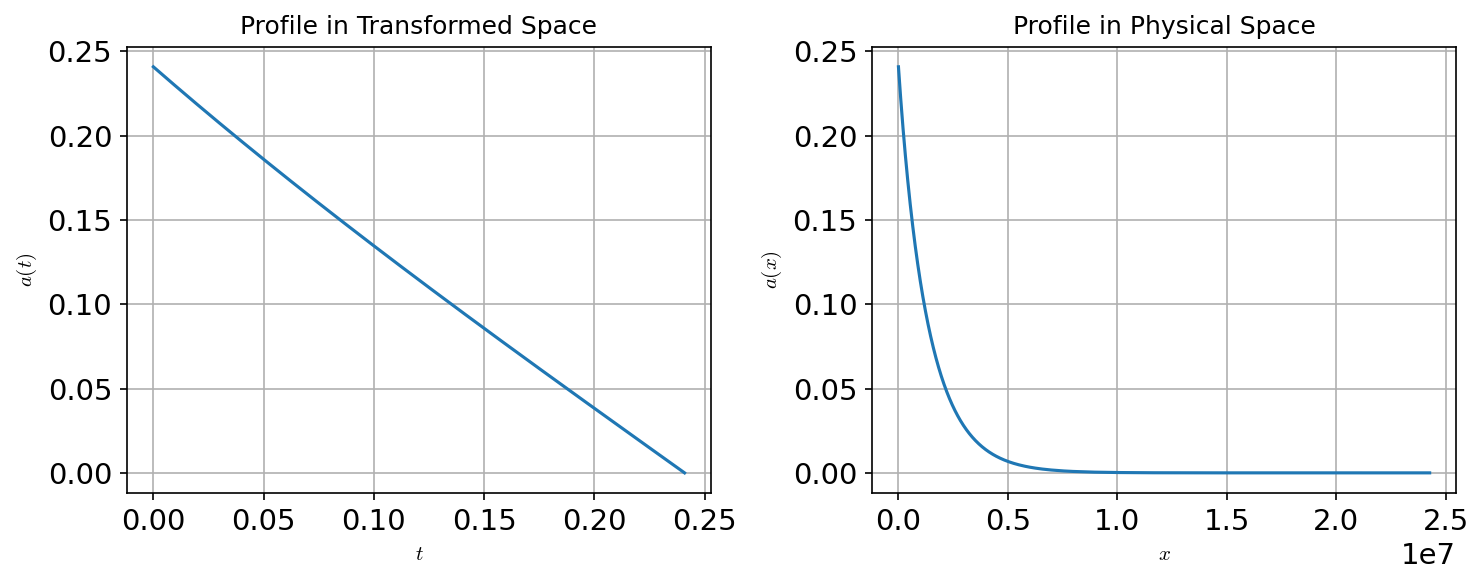

In [ ]:
# new
from scipy.optimize import root

def slope_residual(v_arr):
    v = float(np.abs(v_arr[0]))  # extract scalar from array
    a_prime_x0, _ = get_derivatives_at_zero(v)
    if a_prime_x0 is None:
        return np.inf  # large penalty on failure
    rhs = -v * (aN - aQ) / DQ  # correct sign (check this is your definition)
    return a_prime_x0 - rhs

# --- Root solve ---
v_guess = 1e-7
sol = root(slope_residual, [v_guess], method='hybr')

if sol.success:
    v_root = float(np.abs(sol.x[0]))
    print(f"Converged: v = {v_root:.12e}")
    _, _, sol_list = get_derivatives_at_zero(v_root, plot=True, verb=True, return_solution=True)
else:
    raise RuntimeError(f" Root finding failed: {sol.message}")

#### cross check with compact code

In [ ]:
from RMFsolver.phase_velocity import _vNtoQ_num as v_num
v_num(T=15.0, aQstar = aQ, aN = aN, muQ = muB_star/3) / 3e+8

1.330592460347992e-07

#### convert from MeV$^{-1}$ to nm

In [ ]:
sol_list[0,:] = sol_list[0,:]*const.MeV_fm / 1e6

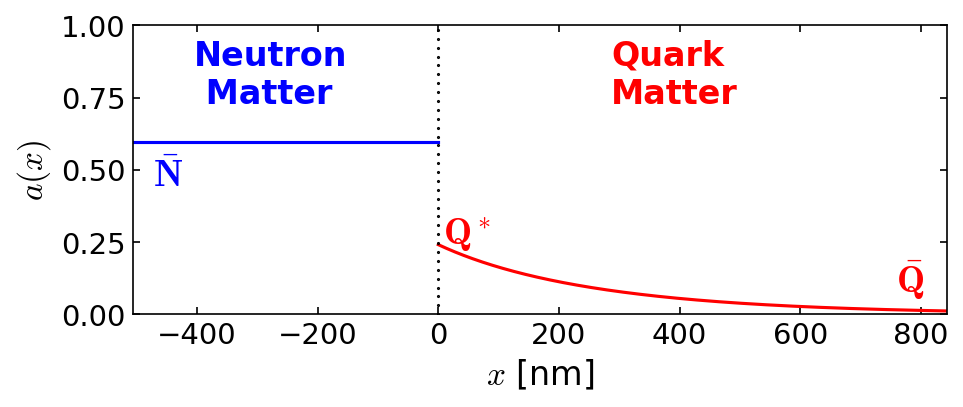

In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

factor = 1.2

plt.figure(figsize=[7, 2.5])
plt.rcParams["figure.dpi"] = 150
mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern for math only
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
})

NN = 760

x_lim_min = -sol_list[0, :NN].max() * 0.6
x_lim_max = sol_list[0, :NN].max()
y_lim_min = 0
y_lim_max = 1.0

x_greater_0 = sol_list[0, :NN] 
a_greater_0 = sol_list[1, :NN]
plt.plot(x_greater_0, a_greater_0, 'r')
plt.plot(np.linspace(x_lim_min, 0, NN), aN * np.ones(NN), 'b')

plt.plot(np.zeros(40), np.linspace(0,1.2,40), '.', markersize=1, color='k')
#plt.plot(np.linspace(x_lim_min, 0, 20), aQ*np.ones(20), '.', markersize=1, color='k')

plt.xlim(x_lim_min, x_lim_max)
plt.ylim(y_lim_min, y_lim_max)

plt.xlabel(rf"$x$ [nm]", fontsize=16)
plt.ylabel(rf"$a(x)$", fontsize=16)
#plt.title(rf"$a(x)$ profile for $T=15$ MeV, $n_{{crit}} = 2.5 n_0$, $\Delta n = n_0/8$", fontsize=14)

plt.text(0.01*x_lim_max, 1.01*aQ, rf"$\mathbf{{Q^*}}$", c='r', fontsize=18)
plt.text(x_lim_max*0.9, 0.08, rf"$\mathbf{{\bar{{Q}}}}$", c='r', fontsize=18)
plt.text(-x_lim_max*0.56, 0.75*aN, rf"$\mathbf{{\bar N}}$", c='b', fontsize=18)
plt.text(-x_lim_max*0.48, 0.73, "Neutron"+'\n'+" Matter", c='b', fontsize=16, fontweight="bold")
plt.text(x_lim_max*0.34, 0.73, "Quark"+'\n'+"Matter", c='r', fontsize=16, fontweight="bold")
#plt.text(-x_lim_max*0.5, aN*1.06, rf"$a_{{\bar N}} = {aN:.3f}$", fontsize=16)
#plt.text(-x_lim_max*0.5, aQ*1.11, rf"$a_{{Q^*}} = {aQ:.3f}$", fontsize=16)

#plt.text(-x_lim_max*0.1, 0.4, rf"$\overset{{\qquad v_{{N\to Q}}}}{{\longleftarrow}}$", fontsize=30)

plt.tick_params(which='both', direction='in', top=True, right=True)

plt.savefig("a(x)_Profile.pdf", bbox_inches="tight")

In [ ]:
x_greater_0 = sol_list[0, :NN] 
nK_greater_0 = sol_list[1, :NN] * 2.625*n0

import numpy as np

# x_greater_0 and a_greater_0 should be 1D arrays of the same length
data = np.column_stack((x_greater_0, nK_greater_0))

np.savetxt(
    "nK_of_x.csv",
    data,
    delimiter=",",
    header="x_greater_0_in_nm,nK_greater_0_in_MeV3",
    comments="for x<0, nK is uniform, which equals to 0.5966564566604293 * 2.625 * n0"   # prevents a leading '# ' in the header
)

In [ ]:
0.5 * 2.625*n0/1e5

16.135356691549916

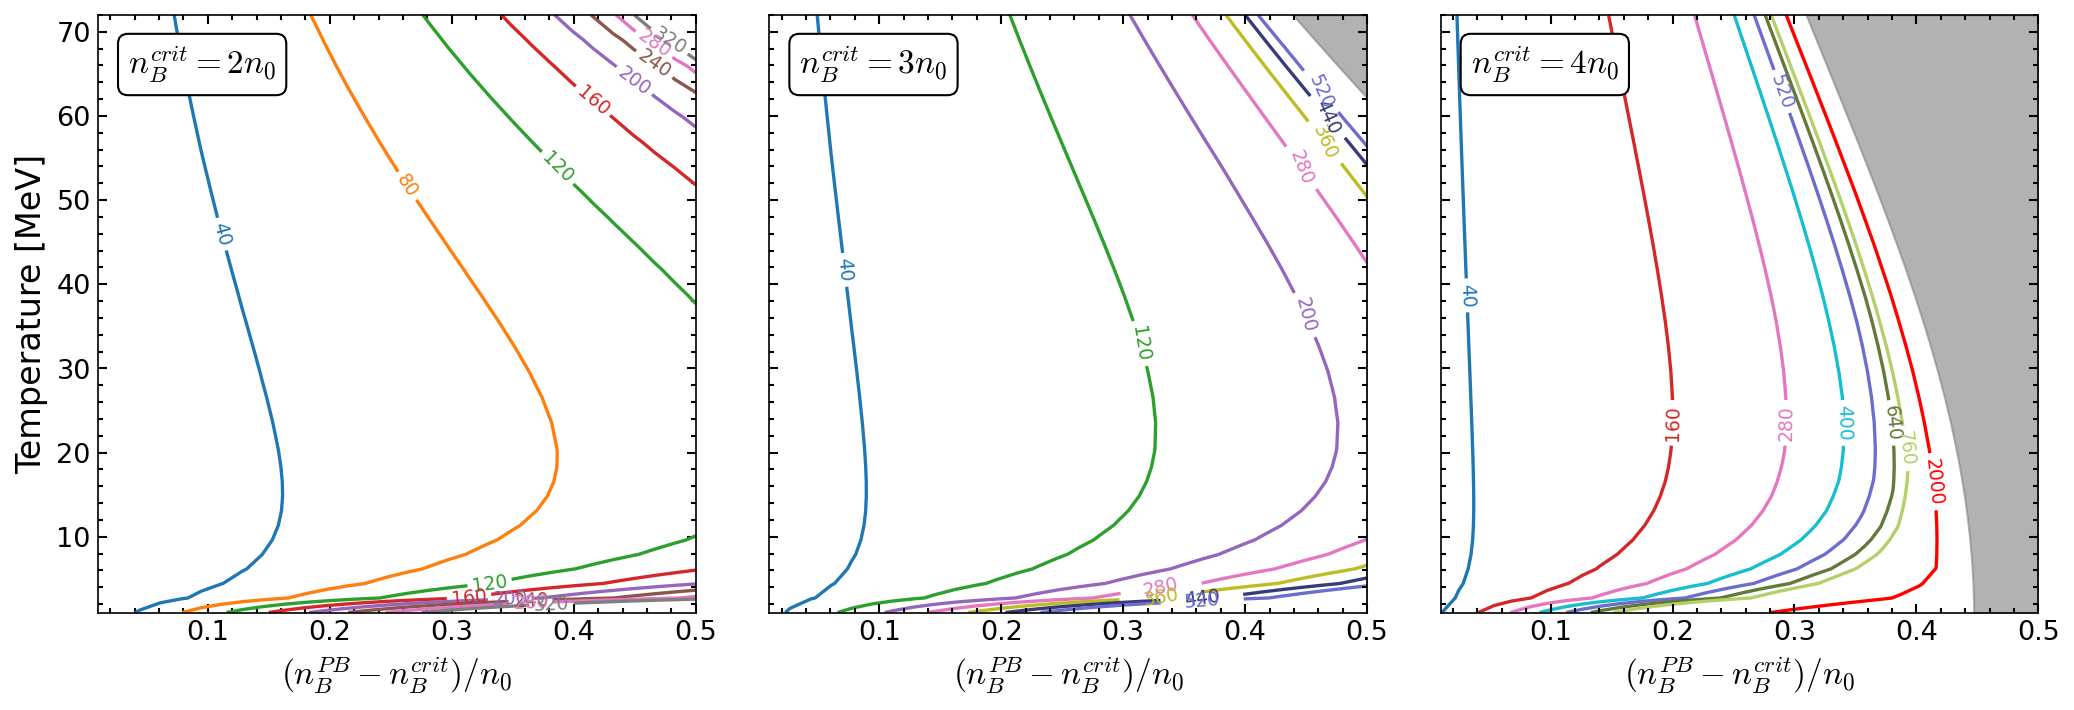

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import quad
from scipy.interpolate import interp1d
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM
import matplotlib.colors as mcolors

# Define n0 (adjust as needed)
n0 = 0.16 * const.MeV_fm**3

nc2, nc3, nc4, nc5 = 2*n0, 3*n0, 4*n0, 4.5*n0
N = 30
path = "/Users/janshao/NSM_related/v_0.002n0/"
path_safe = "/Users/janshao/NSM_related/v_0.015n0_safe/"

al = 0.6

# shaded region
Deln_cut3, T_cut3 = np.load("Shade_n_crit=3.0.npy")
Cut3 = interp1d(T_cut3, Deln_cut3, kind='linear', fill_value="extrapolate")

Deln_cut4, T_cut4 = np.load("Shade_n_crit=4.0.npy")
Cut4 = interp1d(T_cut4, Deln_cut4, kind='linear', fill_value="extrapolate")

Deln_cut4_5, T_cut4_5 = np.load("Shade_n_crit=4.5.npy")
Cut4_5 = interp1d(T_cut4_5, Deln_cut4_5, kind='linear', fill_value="extrapolate")

# ------------------------------------------------------------------------------------
# Levels per subplot
# ------------------------------------------------------------------------------------
levels_11 = np.concatenate([[40+40*i for i in range(8)]])               # 8 levels (2 n0)
levels_12 = np.concatenate([[40+80*i for i in range(7)]])               # 7 levels (3 n0)
levels_21 = np.concatenate([[40+120*i for i in range(7)], [2000]])      # + special 2000 (4 n0)

# Global set of all levels remaining
ALL_LEVELS = np.unique(np.concatenate([levels_11, levels_12, levels_21]))

# ------------------- COLOR MAPPING -------------------
'''
SPECIAL_LEVELS = {2000, 3000}
NORMAL_LEVELS = np.array(sorted([l for l in ALL_LEVELS if l not in SPECIAL_LEVELS]))

cmap = plt.get_cmap('tab20') #copper, winter, tab10, Dark2
norm = mcolors.PowerNorm(gamma=0.8, vmin=NORMAL_LEVELS.min(), vmax=NORMAL_LEVELS.max())

LEVEL_COLOR = {
    lev: (1.0, 0.0, 0.0, 1.0) if lev in SPECIAL_LEVELS else cmap(norm(lev))
    for lev in ALL_LEVELS
}
'''
from matplotlib.colors import ListedColormap

tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0,2,4,6,8,10,12,14,16,18]]  # saturated rows only
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])  # stitch bright colors

cmap = ListedColormap(palette, name="tab20_bright")
def pick(i): return cmap.colors[i % len(cmap.colors)]

LEVEL_COLOR = {lev: pick(k) for k, lev in enumerate(ALL_LEVELS)}
for s in (2000, 3000): LEVEL_COLOR[s] = (1,0,0,1)


def contour_with_fixed_colors(ax, X, Y, Z, levels, **kwargs):
    cols = [LEVEL_COLOR[lev] for lev in levels]
    cs = ax.contour(X, Y, Z, levels=levels, colors=cols, **kwargs)
    ax.clabel(cs, inline=True, fontsize=9, fmt="%d")  # ↑ larger labels
    return cs

# ================= 1 x 3 LAYOUT (square subplots) =================
fig, axs = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
plt.subplots_adjust(left=0.05, right=0.98, bottom=0.12, top=0.95, wspace=0.10)
for ax in axs:
    ax.set_box_aspect(1)  # make each axes square

ax20, ax30, ax40 = axs  # 2n0, 3n0, 4n0

# Common T grid
TT = np.hstack([np.linspace(1, 20, int(N*2/5)), np.linspace(20.5, 72, int(N*3/5))])

# ------------------ panel 1: n_crit = 2 n0 ------------------
D2 = np.linspace(0.01*n0, 0.5*n0, N)
V2 = np.load(path+"v_n_crit=2.0.npy")
X20, Y20 = np.meshgrid(D2/n0, TT)
contour_with_fixed_colors(ax20, X20, Y20, V2, levels_11, linewidths=1.6)
ax20.annotate(r"$n_B^{crit} = 2 n_0$", xy=(0.05, 0.90), xycoords='axes fraction',
              fontsize=16, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ panel 2: n_crit = 3 n0 ------------------
V3  = np.load(path_safe+"v_n_crit=3.0.npy")
t   = np.linspace(0.0, 1.0, N)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut3(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

Dcut = Cut3(TT)
ax30.fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)

contour_with_fixed_colors(ax30, D_grid/n0, T_grid, V3, levels_12, linewidths=1.6, zorder=1)
ax30.set_xlim(0.01, 0.5)
ax30.set_ylim(1, 72)
ax30.annotate(r"$n_B^{crit} = 3 n_0$", xy=(0.05, 0.90), xycoords='axes fraction',
              fontsize=16, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ panel 3: n_crit = 4 n0 ------------------
V4  = np.load(path+"v_n_crit=4.0.npy")
t   = np.linspace(0.0, 1.0, N)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

Dcut = Cut4(TT)
ax40.fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)

contour_with_fixed_colors(ax40, D_grid/n0, T_grid, V4, levels_21, linewidths=1.6, zorder=1)
ax40.set_xlim(0.01, 0.5)
ax40.set_ylim(1, 72)
ax40.annotate(r"$n_B^{crit} = 4 n_0$", xy=(0.05, 0.90), xycoords='axes fraction',
              fontsize=16, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ---------- axes labels & ticks ----------
ax20.set_ylabel("Temperature [MeV]", fontsize=16)
for ax in (ax20, ax30, ax40):
    ax.set_xlabel(r"$(n^{PB}_B - n^{crit}_B) / n_0$", fontsize=16)
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in', top=True, right=True,
                   length=4.5, width=1.0, labelsize=13)
    ax.tick_params(which='minor', length=2.5)
    #ax.set_yscale("log")

#plt.savefig("1by3_Grid.pdf")
# plt.show()

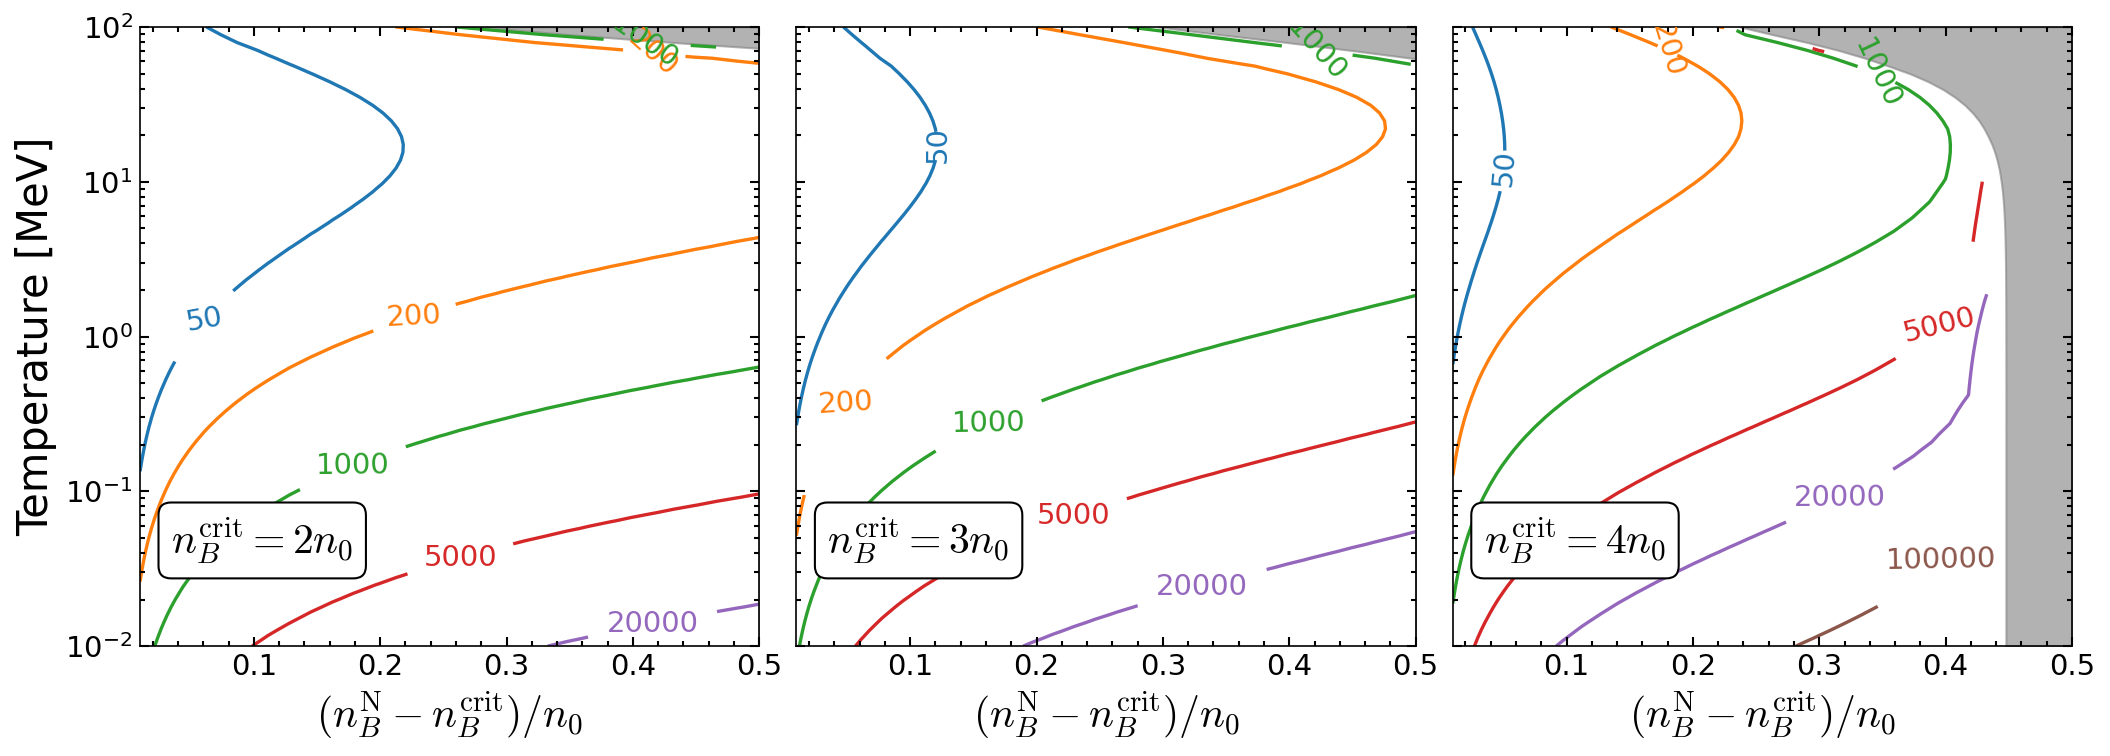

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import interp1d
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM
from matplotlib.colors import ListedColormap

plt.rcParams["figure.dpi"] = 150
mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern for math only
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
})

# ----- physics constants -----
n0 = 0.16 * const.MeV_fm**3
nc2, nc3, nc4 = 2*n0, 3*n0, 4*n0
al = 0.6

# ----- version tag (filenames only) -----
version = "v4"  # v4

# ----- fixed temperature axis (for axes only; we do NOT modify V data) -----
TT = np.logspace(np.log10(0.01), np.log10(100.0), num=80)

# ----- shaded region interpolants (uses saved TT from shade files) -----
Deln_cut2, T_cut2 = np.load(f"Shade_n_crit=2_TTpiece__{version}.npy", allow_pickle=True)
Cut2 = interp1d(T_cut2, Deln_cut2, kind="linear", fill_value="extrapolate")

Deln_cut3, T_cut3 = np.load(f"Shade_n_crit=3_TTpiece__{version}.npy", allow_pickle=True)
Cut3 = interp1d(T_cut3, Deln_cut3, kind="linear", fill_value="extrapolate")

Deln_cut4, T_cut4 = np.load(f"Shade_n_crit=4_TTpiece__{version}.npy", allow_pickle=True)
Cut4 = interp1d(T_cut4, Deln_cut4, kind="linear", fill_value="extrapolate")

# ====== log-spaced contour levels (visual only; does not touch data) -----
_levels = [50, 200, 1000, 5000, 20000, 100000] #np.logspace(np.log10(40), np.log10(40000), 6)
levels_1 = np.unique(np.round(_levels).astype(int))  # for 2 n0
levels_2 = levels_1                                  # for 3 n0
levels_3 = levels_1                                  # for 4 n0
ALL_LEVELS = np.unique(np.concatenate([levels_1, levels_2, levels_3]))

# ----- bright palette (visual only) -----
tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0,2,4,6,8,10,12,14,16,18]]
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])
cmap = ListedColormap(palette, name="tab20_bright")
def pick(i): return cmap.colors[i % len(cmap.colors)]
LEVEL_COLOR = {lev: pick(k) for k, lev in enumerate(ALL_LEVELS)}
for s in (2000, 3000): LEVEL_COLOR[s] = (1,0,0,1)

def contour_with_fixed_colors(ax, X, Y, Z, levels, **kwargs):
    cols = [LEVEL_COLOR[lev] for lev in levels]
    cs = ax.contour(X, Y, Z, levels=levels, colors=cols, **kwargs)
    ax.clabel(cs, inline=True, fontsize=14, fmt="%d")
    return cs

# 1 x 3 layout 
fig, axs = plt.subplots(1, 3, figsize=(14, 5.2), sharey=True)
plt.subplots_adjust(left=0.06, right=0.98, bottom=0.12, top=0.95, wspace=0.06)
for ax in axs:
    ax.set_box_aspect(1)

ax2, ax3, ax4 = axs  # 2n0, 3n0, 4n0

# ------------------ panel 1: n_crit = 2 n0 ------------------
V2 = np.load(f"v_n_crit=2_TTpiece__{version}.npy", allow_pickle=True)
N2D = V2.shape[1]
t2  = np.linspace(0.0, 1.0, N2D)

Dlo   = 0.01 * n0
Dmax2 = np.minimum(0.5 * n0, Cut2(TT) - 0.015 * n0)   # <- same rule as others
Dmax2 = np.maximum(Dmax2, Dlo)
D_grid2 = Dlo + (Dmax2 - Dlo)[:, None] * t2[None, :]
T_grid2 = np.repeat(TT[:, None], N2D, axis=1)

Dcut2 = Cut2(TT)
ax2.fill_betweenx(TT, Dcut2/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)
contour_with_fixed_colors(ax2, D_grid2/n0, T_grid2, V2, levels_1, linewidths=1.6, zorder=1)
ax2.set_xlim(0.01, 0.5)
ax2.set_ylim(0.01, 100)
ax2.annotate(r"$n_B^{\mathrm{crit}} = 2 n_0$", xy=(0.05, 0.15), xycoords='axes fraction',
             fontsize=20, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ panel 2: n_crit = 3 n0 ------------------
V3 = np.load(f"v_n_crit=3_TTpiece__{version}.npy", allow_pickle=True)
N3D = V3.shape[1]
t3  = np.linspace(0.0, 1.0, N3D)

Dlo   = 0.01 * n0
Dmax3 = np.minimum(0.5 * n0, Cut3(TT) - 0.015 * n0)
Dmax3 = np.maximum(Dmax3, Dlo)
D_grid3 = Dlo + (Dmax3 - Dlo)[:, None] * t3[None, :]
T_grid3 = np.repeat(TT[:, None], N3D, axis=1)

Dcut3 = Cut3(TT)
ax3.fill_betweenx(TT, Dcut3/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)
contour_with_fixed_colors(ax3, D_grid3/n0, T_grid3, V3, levels_2, linewidths=1.6, zorder=1)
ax3.set_xlim(0.01, 0.5)
ax3.set_ylim(0.01, 100)
ax3.annotate(r"$n_B^{\mathrm{crit}} = 3 n_0$", xy=(0.05, 0.15), xycoords='axes fraction',
             fontsize=20, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ panel 3: n_crit = 4 n0 ------------------
V4 = np.load(f"v_n_crit=4_TTpiece__{version}.npy", allow_pickle=True)
N4D = V4.shape[1]
t4  = np.linspace(0.0, 1.0, N4D)

Dmax4 = np.minimum(0.5 * n0, Cut4(TT) - 0.015 * n0)
Dmax4 = np.maximum(Dmax4, Dlo)
D_grid4 = Dlo + (Dmax4 - Dlo)[:, None] * t4[None, :]
T_grid4 = np.repeat(TT[:, None], N4D, axis=1)

Dcut4 = Cut4(TT)
ax4.fill_betweenx(TT, Dcut4/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)
contour_with_fixed_colors(ax4, D_grid4/n0, T_grid4, V4, levels_3, linewidths=1.6, zorder=1)
ax4.set_xlim(0.01, 0.5)
ax4.set_ylim(0.01, 100)
ax4.annotate(r"$n_B^{\mathrm{crit}} = 4 n_0$", xy=(0.05, 0.15), xycoords='axes fraction',
             fontsize=20, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ---------- axes labels & ticks ----------
ax2.set_ylabel("Temperature [MeV]", fontsize=20)
for ax in (ax2, ax3, ax4):
    ax.set_xlabel(r"$(n_B^{\mathrm{\rm N}} - n_B^{\mathrm{crit}}) / n_0$", fontsize=20)
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in', top=True, right=True,
                   length=4.5, width=1.0, labelsize=14)
    ax.tick_params(which='minor', length=2.5)
    ax.set_yscale("log")

plt.savefig("1by3_Grid_log_new.pdf")
# plt.show()

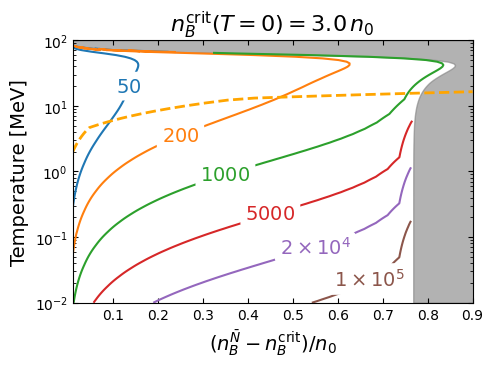

In [10]:
# core3_plot_min.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import RMFsolver.constants as const
from matplotlib.colors import ListedColormap

# ------------------ constants ------------------
n0 = 0.16 * const.MeV_fm**3
nc3 = 3.0 * n0
al = 0.6  # shading alpha

# ------------------ same TT definition as used in solver ------------------
TT = np.logspace(np.log10(0.01), np.log10(100.0), num=160)

# Δn grid
N = 30

# ------------------ load precomputed data ------------------
V3 = np.load("/Users/janshao/NSM_related/archived_pre_2026/npy/v_n_crit=3_TTpiece__v8.npy")
Deln_cut3, T_cut3 = np.load("/Users/janshao/NSM_related/archived_pre_2026/npy/Shade_n_crit=3_TTpiece__v8.npy", allow_pickle=True)
D_dashed, T_dashed = np.load("/Users/janshao/NSM_related/archived_pre_2026/npy/D_line_n_crit=3__v2.npy")
Cut3 = interp1d(T_cut3, Deln_cut3, kind="linear", fill_value="extrapolate")

# ------------------ build grids ------------------
t = np.linspace(0.0, 1.0, N)
Dlo = 0.01 * n0
Dhi = 1.0 * n0
Dmax = np.minimum(Dhi, Cut3(TT) - 0.005 * n0)
Dmax = np.maximum(Dmax, Dlo)

D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

# ------------------ contour levels ------------------
levels = [50, 200, 1000, 5000, 20000, 100000]

# ------------------ bright palette + fixed level colors ------------------
tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0, 2, 4, 6, 8, 10, 12, 14, 16, 18]]
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])
cmap = ListedColormap(palette, name="tab20_bright")

def pick(i):
    return cmap.colors[i % len(cmap.colors)]

LEVEL_COLOR = {lev: pick(k) for k, lev in enumerate(levels)}

# ------------------ label formatter (roman) ------------------
def fmt_func(x):
    x = float(x)
    if x >= 1e4:
        exp = int(np.floor(np.log10(x)))
        mant = int(round(x / 10**exp))
        return rf"$\mathrm{{{mant}}}\times10^{{{exp}}}$"
    return rf"$\mathrm{{{int(x)}}}$"

# ------------------ plot ------------------
fig, ax = plt.subplots(figsize=(5, 3.5))
#ax.set_box_aspect(1)

# grey shaded region
Dcut = Cut3(TT)
ax.fill_betweenx(TT, Dcut / n0, 1.0, color="grey", alpha=al)

# contours
cs = ax.contour(
    D_grid / n0, T_grid, V3,
    levels=levels,
    colors=[LEVEL_COLOR[l] for l in levels],
    linewidths=1.5
)

# label all except 50 and 1e5 using clabel
label_levels = [l for l in levels if l not in (50, 100000)]
#ax.clabel(cs, levels=label_levels, inline=True, fontsize=9, fmt=fmt_func)

# ------------------ manual boxed labels using ax.text ------------------

# --- 50 label (center of blue curve) ---
ax.text(
    0.135, 20.0, r"$\mathrm{50}$",
    color=LEVEL_COLOR[50],
    fontsize=14,
    ha="center", va="center",
    rotation=0,
    bbox=dict(boxstyle="round,pad=0.25",
              facecolor="white", edgecolor="none", alpha=1)
)

ax.text(
    0.25, 3.5, r"$\mathrm{200}$",
    color=LEVEL_COLOR[200],
    fontsize=14,
    ha="center", va="center",
    rotation=0,
    bbox=dict(boxstyle="round,pad=0.25",
              facecolor="white", edgecolor="none", alpha=1)
)

ax.text(
    0.35, 0.9, r"$\mathrm{1000}$",
    color=LEVEL_COLOR[1000],
    fontsize=14,
    ha="center", va="center",
    rotation=0,
    bbox=dict(boxstyle="round,pad=0.25",
              facecolor="white", edgecolor="none", alpha=1)
)

ax.text(
    0.45, 0.23, r"$\mathrm{5000}$",
    color=LEVEL_COLOR[5000],
    fontsize=14,
    ha="center", va="center",
    rotation=0,
    bbox=dict(boxstyle="round,pad=0.25",
              facecolor="white", edgecolor="none", alpha=1)
)

ax.text(
    0.55, 0.07, r"$\mathrm{2\times 10^4}$",
    color=LEVEL_COLOR[20000],
    fontsize=14,
    ha="center", va="center",
    rotation=0,
    bbox=dict(boxstyle="round,pad=0.25",
              facecolor="white", edgecolor="none", alpha=1)
)

# --- 1 x 10^5 label (slightly lower, right side) ---
ax.text(
    0.67, 0.023, r"$\mathrm{1}\times10^{5}$",
    color=LEVEL_COLOR[100000],
    fontsize=14,
    ha="center", va="center",
    bbox=dict(boxstyle="round,pad=0.25",
              facecolor="white", edgecolor="none", alpha=1)
)

ax.plot(D_dashed/n0, T_dashed, ls='--', lw=2, c='orange')

# ------------------ axes styling ------------------
ax.set_xscale("linear")
ax.set_yscale("log")
ax.set_xlim(0.01, 0.9)
ax.set_ylim(0.01, 100)
ax.set_xlabel(r"$(n_B^{\bar N} - n_B^{\rm crit}) / n_0$", fontsize=14)
ax.set_ylabel("Temperature [MeV]", fontsize=14)
ax.set_title(r"$n_B^{\rm crit}(T=0) = 3.0\,n_0$", fontsize=16)
ax.tick_params(which="both", direction="in", top=True, right=True)

#ax.plot(D_grid/n0, 10*np.ones(len(D_grid)), 'k', '--', lw=0.5)
#ax.plot(D_grid/n0, 50*np.ones(len(D_grid)), 'k', '--', lw=0.5)

plt.tight_layout()
plt.subplots_adjust(left=0.16, right=0.96, bottom=0.16, top=0.91)
#plt.savefig("3n0_single_pannel.pdf")
plt.show()

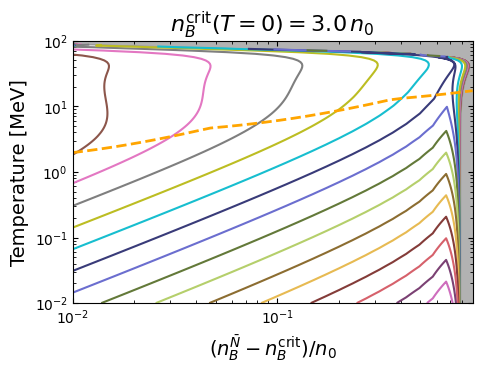

In [ ]:
# core3_plot_min.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import RMFsolver.constants as const
from matplotlib.colors import ListedColormap

# ------------------ constants ------------------
n0 = 0.16 * const.MeV_fm**3
nc3 = 3.0 * n0
al = 0.6  # shading alpha

# ------------------ same TT definition as used in solver ------------------
TT = np.logspace(np.log10(0.01), np.log10(100.0), num=160)

# Δn grid
N = 30

# ------------------ load precomputed data ------------------
V3 = np.load("v_n_crit=3_TTpiece__v10.npy")
Deln_cut3, T_cut3 = np.load("Shade_n_crit=3_TTpiece__v10.npy", allow_pickle=True)
D_dashed, T_dashed = np.load("D_line_n_crit=3__v3.npy")
Cut3 = interp1d(T_cut3, Deln_cut3, kind="linear", fill_value="extrapolate")

# ------------------ build grids ------------------
# log-space parameter in [0, 1]
t = np.linspace(0.0, 1.0, N)

Dlo = 0.01 * n0
Dhi = 1.0 * n0

Dmax = np.minimum(Dhi, Cut3(TT) - 0.005 * n0)
Dmax = np.maximum(Dmax, Dlo)

# log-space interpolation
logDlo  = np.log(Dlo)
logDmax = np.log(Dmax)

D_grid = np.exp(logDlo + (logDmax - logDlo)[:, None] * t[None, :])
T_grid = np.repeat(TT[:, None], N, axis=1)

# ------------------ contour levels ------------------
levels = np.logspace(np.log10(0.5), 5, 20)

# ------------------ bright palette + fixed level colors ------------------
tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0, 2, 4, 6, 8, 10, 12, 14, 16, 18]]
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])
cmap = ListedColormap(palette, name="tab20_bright")

def pick(i):
    return cmap.colors[i % len(cmap.colors)]

LEVEL_COLOR = {lev: pick(k) for k, lev in enumerate(levels)}

# ------------------ label formatter (roman) ------------------
def fmt_func(x):
    x = float(x)
    if x >= 1e4:
        exp = int(np.floor(np.log10(x)))
        mant = int(round(x / 10**exp))
        return rf"$\mathrm{{{mant}}}\times10^{{{exp}}}$"
    return rf"$\mathrm{{{int(x)}}}$"

# ------------------ plot ------------------
fig, ax = plt.subplots(figsize=(5, 3.5))
#ax.set_box_aspect(1)

# grey shaded region
Dcut = Cut3(TT)
ax.fill_betweenx(TT, Dcut / n0, 1.0, color="grey", alpha=al)

# contours
cs = ax.contour(
    D_grid / n0, T_grid, V3,
    levels=levels,
    colors=[LEVEL_COLOR[l] for l in levels],
    linewidths=1.5
)

# label all except 50 and 1e5 using clabel
label_levels = [l for l in levels if l not in (50, 100000)]
#ax.clabel(cs, levels=label_levels, inline=True, fontsize=9, fmt=fmt_func)


ax.plot(D_dashed/n0, T_dashed, ls='--', lw=2, c='orange')
# ------------------ axes styling ------------------
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(0.01, 0.9)
ax.set_ylim(0.01, 100)
ax.set_xlabel(r"$(n_B^{\bar N} - n_B^{\rm crit}) / n_0$", fontsize=14)
ax.set_ylabel("Temperature [MeV]", fontsize=14)
ax.set_title(r"$n_B^{\rm crit}(T=0) = 3.0\,n_0$", fontsize=16)
ax.tick_params(which="both", direction="in", top=True, right=True)

#ax.plot(D_grid/n0, 10*np.ones(len(D_grid)), 'k', '--', lw=0.5)
#ax.plot(D_grid/n0, 50*np.ones(len(D_grid)), 'k', '--', lw=0.5)

plt.tight_layout()
plt.subplots_adjust(left=0.16, right=0.96, bottom=0.16, top=0.91)
#plt.savefig("3n0_single_pannel.pdf")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from tqdm import tqdm
from scipy.interpolate import interp1d
from scipy.optimize import fsolve

from RMFsolver.phase_velocity import Get_aQstar_etaQ, Get_aQstar_etaQ0

n0 = 0.16 * const.MeV_fm**3
m_s = 0
NM_type = "PNM"

def solve_T_at_Deln(Deln, ncrit, N_samp=20):
    # Narrow band first (fast path)
    del_list = np.logspace(-2, 2, N_samp)
    diff_list = []
    for T in del_list:
        aQ, etaQ = Get_aQstar_etaQ(T, ncrit, Deln, m_s, para.paraQMCRMF3, "PNM")
        diff_list.append(aQ*aQ - 2*etaQ)

    # Interpolate and solve; bias the guess toward small Δn (physics prior)
    f = interp1d(del_list, diff_list, kind="linear", fill_value="extrapolate")
    guess = 1.0
    # If sampling found a value closer to zero, use it as a refined guess
    idx_near = int(np.argmin(np.abs(diff_list)))
    guess = float(del_list[idx_near]) if np.abs(diff_list[idx_near]) < np.abs(f(guess)) else guess

    sol = float(fsolve(f, guess)[0])
    return float(np.clip(sol, 0.01, 100.0))

def solve_T_at_Deln0(Deln, ncrit, N_samp=20):
    # Narrow band first (fast path)
    del_list = np.logspace(-2, 2, N_samp)
    diff_list = []
    for T in del_list:
        aQ, etaQ = Get_aQstar_etaQ0(T, ncrit, Deln, m_s, para.paraQMCRMF3, "PNM")
        diff_list.append(aQ*aQ - 2*etaQ)

    # Interpolate and solve; bias the guess toward small Δn (physics prior)
    f = interp1d(del_list, diff_list, kind="linear", fill_value="extrapolate")
    guess = 1.0
    # If sampling found a value closer to zero, use it as a refined guess
    idx_near = int(np.argmin(np.abs(diff_list)))
    guess = float(del_list[idx_near]) if np.abs(diff_list[idx_near]) < np.abs(f(guess)) else guess

    sol = float(fsolve(f, guess)[0])
    return float(np.clip(sol, 0.01, 100.0))

In [ ]:
D_lis_lin = np.linspace(0.01*n0, 0.9*n0, 30)
T_lis_1 = []

for De in tqdm(D_lis_lin):
    T_tmp = solve_T_at_Deln(De, 3*n0)
    T_lis_1.append(T_tmp)

D_lis_log = np.logspace(np.log10(0.01*n0), np.log10(0.9*n0), 30)
T_lis_2 = []

for De in tqdm(D_lis_log):
    T_tmp = solve_T_at_Deln0(De, 3*n0)
    T_lis_2.append(T_tmp)

/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_65946/2371155938.py:31: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  sol = float(fsolve(f, guess)[0])
/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_65946/2371155938.py:31: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  sol = float(fsolve(f, guess)[0])
/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_65946/2371155938.py:31: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  sol = float(fsolve(f, guess)[0])
/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_65946/2371155938.py:31: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  sol = float(fsolve(f, guess)[0])
/var/folders/zx/mchmm24s5sj4l19_jxvlkj38

In [ ]:
np.save('T_lis_1.npy', T_lis_1)
np.save('T_lis_2.npy', T_lis_2)

T_lis_1_ = np.load('T_lis_1.npy')
T_lis_2_ = np.load('T_lis_2.npy')

# $z(t)$ evolution

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import interp1d
from fractions import Fraction

# Read CSV (skip the header row if it exists)
df1 = pd.read_csv("pressure_of_radius_pMeV4_3n0.csv")
df2 = pd.read_csv("pressure_of_radius_pMeV4_4n0.csv")
df3 = pd.read_csv("pressure_of_radius_pMeV4_4.5n0.csv")

# Convert the first column (fractions as strings) to floats
radius1 = df1.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure1 = df1.iloc[:, 1]

radius2 = df2.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure2 = df2.iloc[:, 1]

radius3 = df3.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure3 = df3.iloc[:, 1]

# Convert to numpy arrays if needed
radius1 = radius1.to_numpy(dtype=float)
radius2 = radius2.to_numpy(dtype=float)
radius3 = radius3.to_numpy(dtype=float)
pressure1 = pressure1.to_numpy(dtype=float)
pressure2 = pressure2.to_numpy(dtype=float)
pressure3 = pressure3.to_numpy(dtype=float)

P_of_r1 = interp1d(radius1, pressure1, kind="linear", fill_value="extrapolate")
P_of_r2 = interp1d(radius2, pressure2, kind="linear", fill_value="extrapolate")
P_of_r3 = interp1d(radius3, pressure3, kind="linear", fill_value="extrapolate")

r_test1 = np.linspace(radius1.min(), radius1.max(), 100)
r_test2 = np.linspace(radius2.min(), radius2.max(), 100)
r_test3 = np.linspace(radius3.min(), radius3.max(), 100)
P_test1 = np.array([P_of_r1(ele) for ele in r_test1])
P_test2 = np.array([P_of_r2(ele) for ele in r_test2])
P_test3 = np.array([P_of_r3(ele) for ele in r_test3])

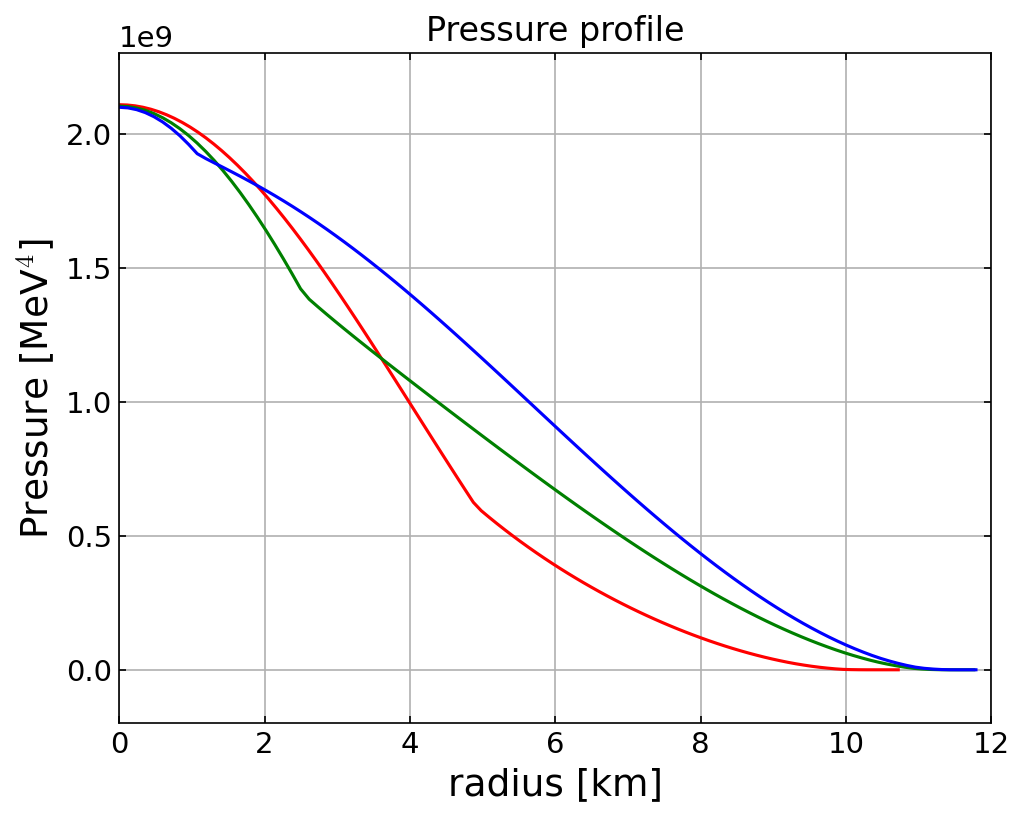

In [ ]:
plt.figure(figsize=[7.5, 5.8])
plt.rcParams["figure.dpi"] = 150

plt.plot(r_test1, P_test1, 'r')
plt.plot(r_test2, P_test2, 'g')
plt.plot(r_test3, P_test3, 'b')

#plt.scatter(6.1, P_of_r(6.1), marker="*", c='r', s=100)
#plt.text(6.2, P_of_r(6.1)*1.1, rf"Critical", fontsize=16)
#plt.plot(radius, pressure, 'b')

plt.title("Pressure profile", fontsize = 16)
plt.xlabel(rf"radius [km]", fontsize = 18)
plt.ylabel(rf"Pressure [MeV$^4$]", fontsize = 18)

plt.xlim(0, 12)
plt.ylim(-0.2e+9, 2.3e+9)
plt.tick_params(which='both', direction='in', top=True, right=True)

plt.grid()
plt.show()

In [ ]:
pressure1[0], pressure1[0]/pressure2[0]

(np.float64(2108766942.576899), np.float64(1.002465984464924))

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, Get_Delta_P_max, _find_muB_muK_star

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

def PNM_n(nB, Temp):
    pre = RMFpressurePNM(
        input_num = nB,
        input_type = "nB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

n0 = 0.16 * const.MeV_fm**3

T = 15
n_kink1 = 2.5 * n0
n_kink2 = 4.0 * n0
n_kink3 = 4.5 * n0
m_s = 0
param = para.paraQMCRMF3
NM_type = "PNM"


# solve for bag constant
P_kink1 = PNM_n(n_kink1, T)
P_kink2 = PNM_n(n_kink2, T)
P_kink3 = PNM_n(n_kink3, T)

In [ ]:
PNM_n(5*n0, 0)/1e9

2.524222900923132

In [ ]:
from RMFsolver.phase_velocity import z_time_evolution1
from tqdm import tqdm

Temp_list = [0.1, 1, 10, 50]

t1 = []
z1 = []
t2 = []
z2 = []
t3 = []
z3 = []
P_cr1 = []
P_cr2 = []
P_cr3 = []

time_up = 100

for Te in tqdm(Temp_list):
    tt1, zz1, P_crit1 = z_time_evolution1(
        Pressure_arr = pressure1, 
        radius_arr = radius1,
        P_kink = P_kink1,
        T = Te, 
        Interp1d_Num = 10,
        t_up = time_up,
    )
    
    tt2, zz2, P_crit2 = z_time_evolution1(
        Pressure_arr = pressure2, 
        radius_arr = radius2,
        P_kink = P_kink2,
        T = Te, 
        Interp1d_Num = 10,
        t_up = time_up,
    )
    
    tt3, zz3, P_crit3 = z_time_evolution1(
        Pressure_arr = pressure3, 
        radius_arr = radius3,
        P_kink = P_kink3,
        T = Te, 
        Interp1d_Num = 10,
        t_up = time_up,
    )

    t1.append(tt1)
    z1.append(zz1)
    
    t2.append(tt2)
    z2.append(zz2)

    t3.append(tt3)
    z3.append(zz3)

    P_cr1.append(P_crit1)
    P_cr2.append(P_crit2)
    P_cr3.append(P_crit3)

100%|██████████████████████████████████████████████████████████| 4/4 [29:25<00:00, 441.33s/it]


In [ ]:
n_cr1 = []
n_cr2 = []
n_cr3 = []

for i in tqdm(range(len(Temp_list))):
    
    n_crit1 = fsolve(lambda x: PNM_n(x, Temp_list[i]) - P_cr1[i], x0=3.0*n0)[0]
    n_crit2 = fsolve(lambda x: PNM_n(x, Temp_list[i]) - P_cr2[i], x0=3.0*n0)[0]
    n_crit3 = fsolve(lambda x: PNM_n(x, Temp_list[i]) - P_cr3[i], x0=3.0*n0)[0]

    n_cr1.append(n_crit1)
    n_cr2.append(n_crit2)
    n_cr3.append(n_crit3)

100%|███████████████████████████████████████████████████████████| 4/4 [00:35<00:00,  8.78s/it]


NameError: name 't1' is not defined

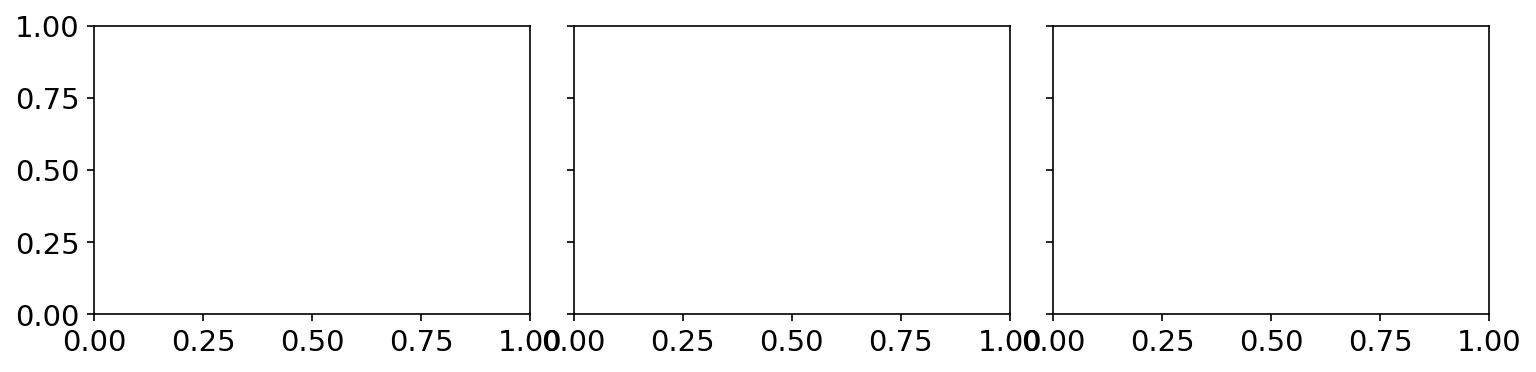

In [ ]:
import matplotlib as mpl
import numpy as np
import matplotlib.pyplot as plt

# --- style ---
mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern math
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
})

fig, axs = plt.subplots(1, 3, figsize=(12, 2.5), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.1, hspace=0.05)

t_upp = 55
y_down = 1e-8
tline = np.linspace(0, t_upp, 100)
zeroline = np.zeros_like(tline)

# helper for panel titles
def crit_title(mean_n_over_n0):
    return r"$n_B^{\mathrm{crit}} = $" + f"{mean_n_over_n0:.2f}" + r"$\,n_0$"

# color scheme for temperatures
colors = ['#0072B2', '#009E73', '#D55E00', '#E69F00']
labels = [r"$T=0.1$ MeV", r"$T=1$ MeV", r"$T=10$ MeV", r"$T=50$ MeV"]

# define y ticks (10^0 down to 10^-7)
y_ticks = [1e0, 1e-1, 1e-3, 1e-5, 1e-7]
y_ticklabels = [r"$1$", r"$10^{-1}$", r"$10^{-3}$",
                r"$10^{-5}$", r"$10^{-7}$"]

# ---------- panel loop ----------
for ax, tset, zset, ncr in zip(axs, [t1, t2, t3], [z1, z2, z3], [n_cr1, n_cr2, n_cr3]):
    for c, lbl, t, z in zip(colors, labels, tset, zset):
        ax.plot(t, z, lw=1.5, c=c, label=lbl)
    ax.plot(tline, zeroline, 'k', lw=1)
    ax.set_xlim(5e-4, t_upp)
    ax.set_ylim(y_down, 2.0)
    ax.set_yscale("log")
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_ticklabels)
    ax.set_xlabel(r"time [s]", fontsize=20)
    ax.set_title(crit_title(np.mean(ncr) / n0), fontsize=20)
    ax.tick_params(which='both', direction='in', top=True, right=True)
    ax.legend(fontsize=18, loc="upper right", frameon=True)

axs[0].set_ylabel(r"$z$ [$\mathrm{km}$]", fontsize=20)

plt.savefig("Various_z(t)_new_idea_log.pdf", bbox_inches="tight")
# plt.show()

# No input profile

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, Get_Delta_P_max, _find_muB_muK_star

n0 = 0.16 * const.MeV_fm**3

In [ ]:
from RMFsolver.phase_velocity import z_time_evolution2
from tqdm import tqdm

Temp_list = [0.1, 1, 10, 50]

#t1 = []
#z1 = []
t2 = []
z2 = []
#t3 = []
#z3 = []
#P_cr1 = []
P_cr2 = []
#P_cr3 = []

time_up = 100

for Te in tqdm(Temp_list):
#    tt1, zz1 = z_time_evolution2(
#        dP_over_dr = 2e8,
#        n_crit = 2*n0,
#        T = Te, 
#        Interp1d_Num = 10,
#        t_up = time_up,
#    )
    
    tt2, zz2 = z_time_evolution2(
        dP_over_dr = 2e8,
        n_crit = 3*n0,
        T = Te, 
        Interp1d_Num = 10,
        t_up = time_up,
    )

#    tt3, zz3 = z_time_evolution2(
#        dP_over_dr = 2e8,
#        n_crit = 4*n0,
#        T = Te, 
#        Interp1d_Num = 10,
#        t_up = time_up,
#    )

    #t1.append(tt1)
    #z1.append(zz1)
    
    t2.append(tt2)
    z2.append(zz2)

    #t3.append(tt3)
    #z3.append(zz3)


00%|███████████████████████████████████████████████████████████████████████████| 4/4 [05:32<00:00, 83.07s/it]

In [ ]:
#ttt1, zzz1 = t1, z1
ttt2, zzz2 = t2, z2
#ttt3, zzz3 = t3, z3

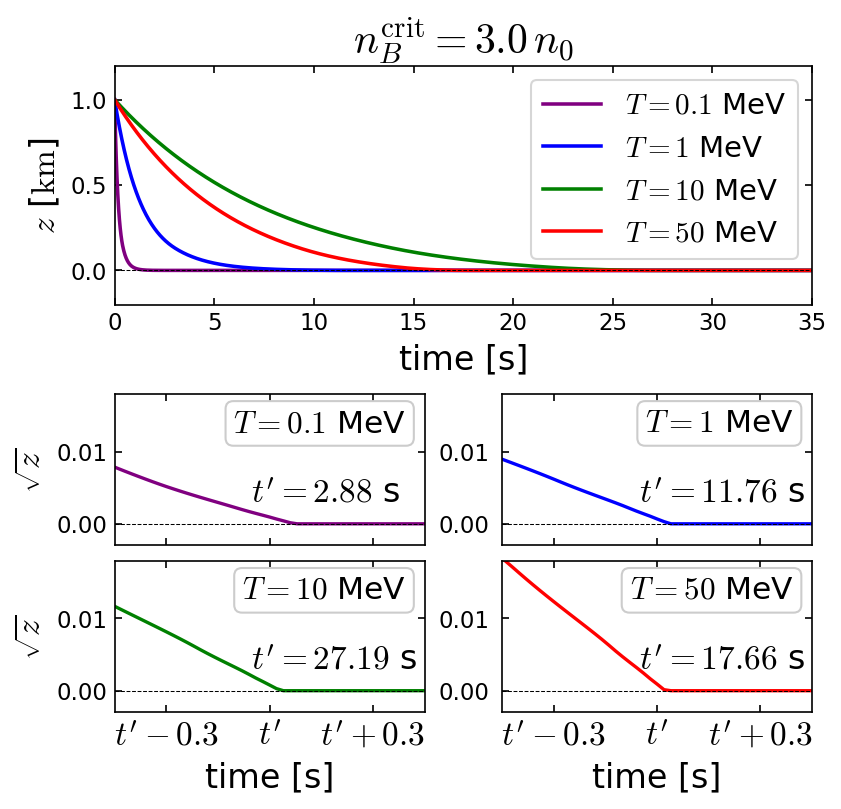

In [ ]:
import matplotlib as mpl
import numpy as np
import matplotlib.pyplot as plt

# ---------------- style ----------------
mpl.rcParams.update({
    "mathtext.fontset": "cm",
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

def crit_title(mean_n_over_n0):
    return rf"$n_B^{{\rm crit}} = {mean_n_over_n0:.2f}\,n_0$"

colors = ['purple', 'b', 'g', 'r']
labels = [r"$T=0.1$ MeV", r"$T=1$ MeV", r"$T=10$ MeV", r"$T=50$ MeV"]

# --------- middle-panel data ----------
tset, zset = t2, z2
ncr = 3 * n0

t_p, t_b, t_g, t_r = tset
z_p, z_b, z_g, z_r = zset

# --------- left plot limits ----------
t_upp = 35
y_down = -0.2
tline = np.linspace(0, t_upp, 200)
zeroline = np.zeros_like(tline)

# --------- tail control ----------
dt_p, dt_b, dt_g, dt_r = 1.0, 2.0, 4.0, 6.0
z_eps = 1e-6

def t_end_near_zero(t, z, eps=z_eps):
    zc = np.clip(z, 0.0, None)
    idx = np.where(zc <= eps)[0]
    return float(t[idx[0]]) if idx.size else float(t[-1])

# =================================================
# LAYOUT: upper 口, lower 田
# =================================================
fig = plt.figure(figsize=(4*1.5, 5.6))
gs = fig.add_gridspec(2, 1, height_ratios=[0.75, 1.0], hspace=0.32)
txloc, tyloc = 0.44, 0.28

# --------- upper：口 ----------
axL = fig.add_subplot(gs[0, 0])

axL.plot(t_p, z_p, lw=1.7, c=colors[0], label=labels[0])
axL.plot(t_b, z_b, lw=1.7, c=colors[1], label=labels[1])
axL.plot(t_g, z_g, lw=1.7, c=colors[2], label=labels[2])
axL.plot(t_r, z_r, lw=1.7, c=colors[3], label=labels[3])

axL.plot(tline, zeroline, 'k--', lw=0.5)
axL.set_xlim(0, t_upp)
axL.set_ylim(y_down, 1.2)
axL.set_xlabel(r"time [s]", fontsize=16)
axL.set_ylabel(r"$z$ [$\mathrm{km}$]", fontsize=16)
axL.set_title(rf"$n_B^{{\rm crit}} = {ncr/n0:.1f}\,n_0$", fontsize=20)
axL.legend(fontsize=14, frameon=True)
axL.tick_params(direction='in', top=True, right=True)

# --------- lower：田 (2×2) ----------
# FIX: keep the 2×2 uniform so all four small panels have the same shape
gsR = gs[1, 0].subgridspec(2, 2, hspace=0.1, wspace=0.25)
ax11 = fig.add_subplot(gsR[0, 0])
ax12 = fig.add_subplot(gsR[0, 1])
ax21 = fig.add_subplot(gsR[1, 0])
ax22 = fig.add_subplot(gsR[1, 1])

# helper: legend-like box with NO line handle
def legend_box(ax, text, loc="upper right", fontsize=14):
    x, y, ha, va = 0.94, 0.90, "right", "top"
    if loc == "upper left":
        x, y, ha, va = 0.06, 0.90, "left", "top"
    elif loc == "lower left":
        x, y, ha, va = 0.06, 0.10, "left", "bottom"
    elif loc == "lower right":
        x, y, ha, va = 0.94, 0.10, "right", "bottom"

    ax.text(
        x, y, text,
        transform=ax.transAxes,
        ha=ha, va=va,
        fontsize=fontsize,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor="0.8",
            linewidth=1.0
        )
    )

# --- purple ---
te = t_end_near_zero(t_p, z_p)
t0, t1 = max(0.0, te - dt_p), te
ax11.plot(t_p, np.sqrt(np.clip(z_p, 0.0, None)), lw=1.6, c=colors[0])
ax11.set_xlim(t1 - 0.45, t1 + 0.45)
ax11.axhline(0, lw=0.5, c='k', ls='--')
legend_box(ax11, labels[0], loc="upper right", fontsize=15)
ax11.text(txloc, tyloc, rf"$t' = {t1:.2f}$ s", transform=ax11.transAxes, fontsize=16)
ax11.tick_params(direction='in', top=True, right=True)
ax11.set_xticks([t1-0.3, t1, t1+0.3])
ax11.set_xticklabels([r"$t'-0.3$", r"$t'$", r"$t'+0.3$"], fontsize=14)

# --- blue ---
te = t_end_near_zero(t_b, z_b)
t0, t1 = max(0.0, te - dt_b), te
ax12.plot(t_b, np.sqrt(np.clip(z_b, 0.0, None)), lw=1.6, c=colors[1])
ax12.set_xlim(t1 - 0.45, t1 + 0.45)
ax12.axhline(0, lw=0.5, c='k', ls='--')
legend_box(ax12, labels[1], loc="upper right", fontsize=15)
ax12.text(txloc, tyloc, rf"$t' = {t1:.2f}$ s", transform=ax12.transAxes, fontsize=16)
ax12.tick_params(direction='in', top=True, right=True)
ax12.set_xticks([t1-0.3, t1, t1+0.3])
ax12.set_xticklabels([r"$t'-0.3$", r"$t'$", r"$t'+0.3$"], fontsize=14)

# --- green ---
te = t_end_near_zero(t_g, z_g)
t0, t1 = max(0.0, te - dt_g), te
ax21.plot(t_g, np.sqrt(np.clip(z_g, 0.0, None)), lw=1.6, c=colors[2])
ax21.set_xlim(t1 - 0.45, t1 + 0.45)
ax21.axhline(0, lw=0.5, c='k', ls='--')
legend_box(ax21, labels[2], loc="upper right", fontsize=15)
ax21.text(txloc, tyloc, rf"$t' = {t1:.2f}$ s", transform=ax21.transAxes, fontsize=16)
ax21.tick_params(direction='in', top=True, right=True)
ax21.set_xticks([t1-0.3, t1, t1+0.3])
ax21.set_xticklabels([r"$t'-0.3$", r"$t'$", r"$t'+0.3$"], fontsize=16)

# --- red ---
te = t_end_near_zero(t_r, z_r)
t0, t1 = max(0.0, te - dt_r), te
ax22.plot(t_r, np.sqrt(np.clip(z_r, 0.0, None)), lw=1.6, c=colors[3])
ax22.set_xlim(t1 - 0.45, t1 + 0.45)
ax22.axhline(0, lw=0.5, c='k', ls='--')
legend_box(ax22, labels[3], loc="upper right", fontsize=15)
ax22.text(txloc, tyloc, rf"$t' = {t1:.2f}$ s", transform=ax22.transAxes, fontsize=16)
ax22.tick_params(direction='in', top=True, right=True)
ax22.set_xticks([t1-0.3, t1, t1+0.3])
ax22.set_xticklabels([r"$t'-0.3$", r"$t'$", r"$t'+0.3$"], fontsize=16)


# shared labels
ax11.set_ylabel(r"$\sqrt{z}$", fontsize=16)
ax21.set_ylabel(r"$\sqrt{z}$", fontsize=16)
ax21.set_xlabel(r"time [s]", fontsize=16)
ax22.set_xlabel(r"time [s]", fontsize=16)

ax11.set_xticklabels([])
ax12.set_xticklabels([])

# ---- rotate y-tick labels for right column to avoid overlap ----
for ax in (ax12, ax22):
    ax.tick_params(axis='y', labelrotation=0, pad=6)
    for lab in ax.get_yticklabels():
        lab.set_ha('right')

# ---- enforce uniform y-limits for the 2×2 subplots ----
for ax in (ax11, ax12, ax21, ax22):
    ax.set_ylim(-0.003, 0.018)

plt.savefig("z_t.pdf", bbox_inches="tight")
# plt.show()

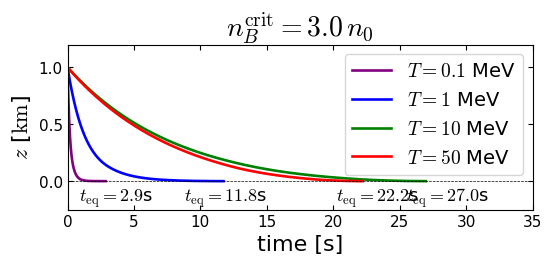

In [ ]:
import matplotlib as mpl
import numpy as np
import matplotlib.pyplot as plt

# ---------------- style ----------------
mpl.rcParams.update({
    "mathtext.fontset": "cm",
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

def crit_title(mean_n_over_n0):
    return rf"$n_B^{{\rm crit}} = {mean_n_over_n0:.2f}\,n_0$"

colors = ['purple', 'b', 'g', 'r']
labels = [r"$T=0.1$ MeV", r"$T=1$ MeV", r"$T=10$ MeV", r"$T=50$ MeV"]

# --------- middle-panel data ----------
tset, zset = t2, z2
ncr = 3 * n0

t_p, t_b, t_g, t_r = tset
z_p, z_b, z_g, z_r = zset

# --------- left plot limits ----------
t_upp = 35
y_down = -0.25
tline = np.linspace(0, t_upp, 200)
zeroline = np.zeros_like(tline)

# --------- tail control ----------
dt_p, dt_b, dt_g, dt_r = 1.0, 2.0, 4.0, 6.0
z_eps = 1e-6

def t_end_near_zero(t, z, eps=z_eps):
    zc = np.clip(z, 0.0, None)
    idx = np.where(zc <= eps)[0]
    return int(idx[0]) if idx.size else float(t[-1])

idx_tep = t_end_near_zero(t_p, z_p)
idx_teb = t_end_near_zero(t_b, z_b)
idx_teg = t_end_near_zero(t_g, z_g)
idx_ter = t_end_near_zero(t_r, z_r)
tep = t_p[idx_tep]
teb = t_b[idx_teb]
teg = t_g[idx_teg]
ter = t_r[idx_ter]

# =================================================
# LAYOUT: upper 口, lower 田
# =================================================
fig = plt.figure(figsize=(4*1.5, 5.8))
gs = fig.add_gridspec(2, 1, height_ratios=[0.75, 1.0], hspace=0.32)
txloc, tyloc = 0.44, 0.28

# --------- upper：口 ----------
axL = fig.add_subplot(gs[0, 0])

axL.plot(t_p[:idx_tep], z_p[:idx_tep], lw=1.9, c=colors[0], label=labels[0])
axL.plot(t_b[:idx_teb], z_b[:idx_teb], lw=1.9, c=colors[1], label=labels[1])
axL.plot(t_g[:idx_teg], z_g[:idx_teg], lw=1.9, c=colors[2], label=labels[2])
axL.plot(t_r[:idx_ter], z_r[:idx_ter], lw=1.9, c=colors[3], label=labels[3])

axL.text(tep-2, -0.18, rf'$t_{{\rm eq}} = {tep:.1f}$s', fontsize=13)
axL.text(teb-3, -0.18, rf'$t_{{\rm eq}} = {teb:.1f}$s', fontsize=13)
axL.text(teg-1.5, -0.18, rf'$t_{{\rm eq}} = {teg:.1f}$s', fontsize=13)
axL.text(ter-2, -0.18, rf'$t_{{\rm eq}} = {ter:.1f}$s', fontsize=13)

axL.plot(tline, zeroline, 'k--', lw=0.5)
axL.set_xlim(0, t_upp)
axL.set_ylim(y_down, 1.2)
axL.set_xlabel(r"time [s]", fontsize=16)
axL.set_ylabel(r"$z$ [$\mathrm{km}$]", fontsize=16)
axL.set_title(rf"$n_B^{{\rm crit}} = {ncr/n0:.1f}\,n_0$", fontsize=20)
axL.legend(fontsize=14, frameon=True)
axL.tick_params(direction='in', top=True, right=True)

#plt.savefig("z_t_new.pdf", bbox_inches="tight")
# plt.show()

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, Get_Delta_P_max, _find_muB_muK_star

n0 = 0.16 * const.MeV_fm**3

In [ ]:
from RMFsolver.phase_velocity import z_time_evolution3
from tqdm import tqdm

Temp_list = [0.1, 1, 10, 50]

t2 = []
z2 = []
P_cr2 = []

time_up = 100

for Te in tqdm(Temp_list):
    tt2, zz2 = z_time_evolution3(
        dn_over_dr = 3*n0/10,
        n_crit0 = 3*n0,
        z0 = 0.01,
        T = Te, 
        Interp1d_Num = 10,
        t_up = time_up,
    )
    
    t2.append(tt2)
    z2.append(zz2)


00%|█████████████████████████████████████████████| 4/4 [05:38<00:00, 84.60s/it]

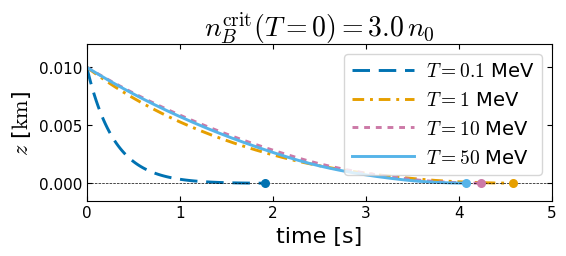

In [ ]:
import matplotlib as mpl
import numpy as np
import matplotlib.pyplot as plt

# ---------------- style ----------------
mpl.rcParams.update({
    "mathtext.fontset": "cm",
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

def crit_title(mean_n_over_n0):
    return rf"$n_B^{{\rm crit}} = {mean_n_over_n0:.2f}\,n_0$"

# ---------------- color + linestyle (no black) ----------------
# Colorblind-robust colors + custom dash patterns (avoid faint ":" dotted line)
colors = [
    "#0072B2",  # blue
    "#E69F00",  # orange
    "#CC79A7",  # purple/magenta
    "#56B4E9",  # sky blue
]

# Custom linestyles (Matplotlib dash tuples): (offset, (on_off_seq...))
linestyles = [
    (0, (6, 3)),         # dashed: 6 on, 3 off
    (0, (4, 2, 1, 2)),   # dash-dot: 4 on,2 off,1 on,2 off
    (0, (2, 2)),         # short dashed (replaces ":")
    "-",                # solid
]

labels = [r"$T=0.1$ MeV", r"$T=1$ MeV", r"$T=10$ MeV", r"$T=50$ MeV"]

# --------- middle-panel data ----------
tset, zset = t2, z2
ncr = 3 * n0

t_p, t_b, t_g, t_r = tset
z_p, z_b, z_g, z_r = zset

# --------- left plot limits ----------
t_upp = 5
y_down = -0.0015
tline = np.linspace(0, t_upp, 200)
zeroline = np.zeros_like(tline)

# --------- tail control ----------
dt_p, dt_b, dt_g, dt_r = 1.0, 2.0, 4.0, 6.0
z_eps = 1e-6

def t_end_near_zero(t, z, eps=z_eps):
    zc = np.clip(z, 0.0, None)
    idx = np.where(zc <= eps)[0]
    return int(idx[0]) if idx.size else int(len(t) - 1)

idx_tep = t_end_near_zero(t_p, z_p)
idx_teb = t_end_near_zero(t_b, z_b)
idx_teg = t_end_near_zero(t_g, z_g)
idx_ter = t_end_near_zero(t_r, z_r)
tep = t_p[idx_tep]
teb = t_b[idx_teb]
teg = t_g[idx_teg]
ter = t_r[idx_ter]

# ---------------- figure ----------------
fig = plt.figure(figsize=(4*1.5, 5.5))
gs = fig.add_gridspec(2, 1, height_ratios=[0.75, 1.0], hspace=0.32)
txloc, tyloc = 0.44, 0.28

axL = fig.add_subplot(gs[0, 0])

lw_main = 2.1

axL.plot(t_p[:idx_tep], z_p[:idx_tep], lw=lw_main, c=colors[0], ls=linestyles[0], label=labels[0])
axL.plot(t_b[:idx_teb], z_b[:idx_teb], lw=lw_main, c=colors[1], ls=linestyles[1], label=labels[1])
axL.plot(t_g[:idx_teg], z_g[:idx_teg], lw=lw_main, c=colors[2], ls=linestyles[2], label=labels[2])
axL.plot(t_r[:idx_ter], z_r[:idx_ter], lw=lw_main, c=colors[3], ls=linestyles[3], label=labels[3])

# End markers at z=0
axL.scatter(tep, 0, c=colors[0], s=30, zorder=5)
axL.scatter(teb, 0, c=colors[1], s=30, zorder=5)
axL.scatter(teg, 0, c=colors[2], s=30, zorder=5)
axL.scatter(ter, 0, c=colors[3], s=30, zorder=5)

# Zero line
axL.plot(tline, zeroline, 'k--', lw=0.5)

# Axes cosmetics
axL.set_xlim(0, t_upp)
axL.set_ylim(y_down, 0.012)
axL.set_xlabel(r"time [s]", fontsize=16)
axL.set_ylabel(r"$z$ [$\mathrm{km}$]", fontsize=16)
axL.set_title(rf"$n_B^{{\rm crit}}(T=0) = {ncr/n0:.1f}\,n_0$", fontsize=20)

# Legend: longer handles help show dash patterns clearly
axL.legend(fontsize=14, frameon=True, handlelength=3.2, handletextpad=0.6)

axL.tick_params(direction='in', top=True, right=True)

plt.savefig("z_t_small.pdf", bbox_inches="tight")
# plt.show()

In [ ]:
from RMFsolver.phase_velocity import vNtoQ_nc

start = time.time()
v, _ = vNtoQ_nc(
    T = 0.01,
    n_crit = 3*n0, 
    Deln = 0.2*n0,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
)
end = time.time()

v, end - start

(np.float64(21350.120131351166), 2.0846831798553467)

In [ ]:
from RMFsolver.phase_velocity import vNtoQ_Pc_fixB
import RMFsolver.RMFparameter as para
import time as time

start = time.time()
v, _ = vNtoQ_Pc_fixB(
    T = 15,
    P_crit0 = 6.1e8, 
    DelP = 5e5,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
)
end = time.time()

v, end - start

(np.float64(2.826389509801803), 5.403594017028809)

In [ ]:
PNM_n(3.9*n0, 0)/1e8

13.044560065229293

In [ ]:
DelP max = 13e+8